In [1]:
import sys
import sklearn
print(sys.version)
print(sklearn.__version__)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
1.8.0


In [11]:
import pandas as pd

df = pd.read_csv('../data/raw/initial_data.csv')

display(df.head(10))

print(df.dtypes)

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,2024-01-01 00:00:00,0.457786,0.469524,0.396368,0.445441,0.692057,Normal
1,2024-01-01 00:30:00,0.351956,0.465545,0.451184,0.458729,0.539874,Normal
2,2024-01-01 01:00:00,0.482948,0.285415,0.408289,0.470360,0.614724,Normal
3,2024-01-01 01:30:00,0.628838,0.482095,0.512308,0.576241,0.757044,Normal
4,2024-01-01 02:00:00,0.335974,0.624741,0.672021,0.373004,0.673981,Normal
5,2024-01-01 02:30:00,0.335977,0.355389,0.382767,0.361111,0.618607,Normal
6,2024-01-01 03:00:00,0.638202,0.667102,0.643164,0.611004,0.703225,Normal
7,2024-01-01 03:30:00,0.502906,0.591854,0.381205,0.407144,0.718050,Normal
8,2024-01-01 04:00:00,0.296754,0.427858,0.371512,0.311121,0.663703,Normal
9,2024-01-01 04:30:00,0.465427,0.507400,0.616383,0.404446,0.668736,Normal


Timestamp                object
Electricity_Consumed    float64
Temperature             float64
Humidity                float64
Wind_Speed              float64
Avg_Past_Consumption    float64
Anomaly_Label            object
dtype: object


In [12]:
%run ../src/data/train.py

1. Загрузка данных.
Размер Train: 2100 строк, из них аномалий: 91
2. Инициализация.
3. Запуск кросс-валидации.
   [Dummy (Most Frequent)] PR-AUC: 0.043 ± 0.000, Время: 0.0с


C:\Users\Charlie\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Charlie\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Charlie\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave '

   [Logistic Regression L2] PR-AUC: 0.083 ± 0.053, Время: 0.47с


C:\Users\Charlie\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Charlie\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Charlie\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
 

   [Logistic Regression L1] PR-AUC: 0.143 ± 0.147, Время: 0.43с
   [kNN (k=25)] PR-AUC: 0.489 ± 0.156, Время: 0.56с
   [Decision Tree (max_depth=5)] PR-AUC: 0.516 ± 0.207, Время: 0.43с
   [Random Forest] PR-AUC: 0.738 ± 0.148, Время: 2.56с
   [Gradient Boosting] PR-AUC: 0.579 ± 0.269, Время: 6.54с
4. Подбор гиперпараметров для Gradient Boosting.
   Лучшие параметры: {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__max_iter': 100}
   Лучший PR-AUC: 0.622
5. Сохранение результатов...

Лучшая модель: Random Forest (PR-AUC: 0.738)
Обучение финальной модели на Train.
Модель и метрики сохранены.


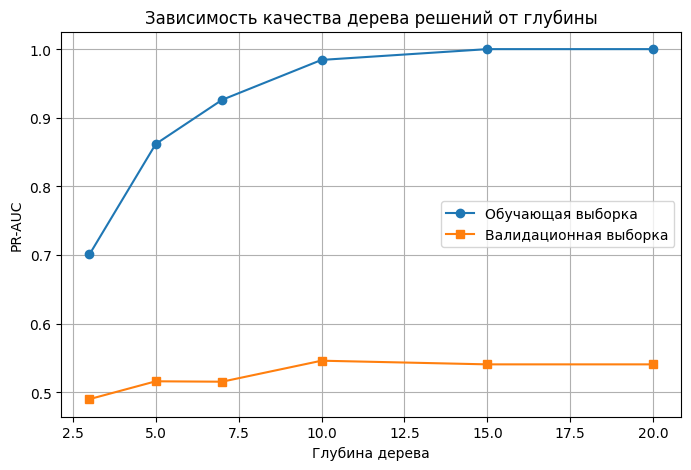

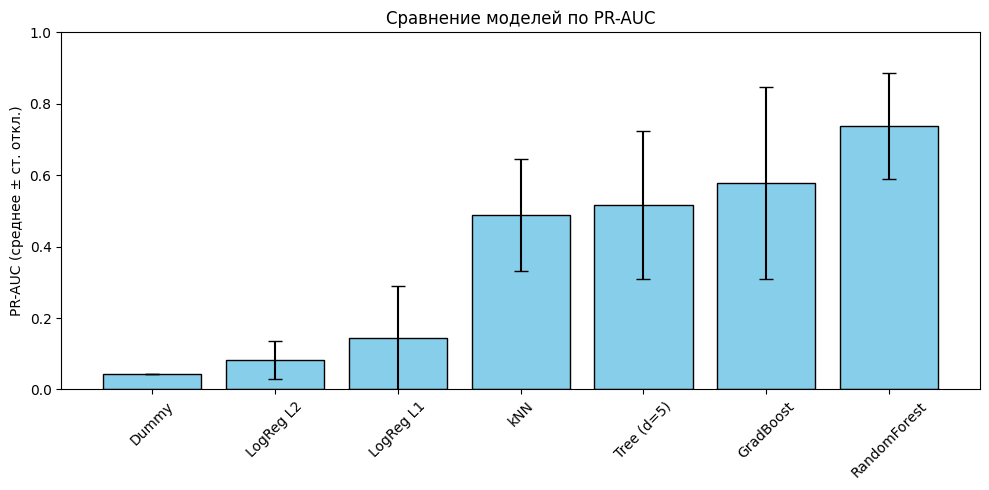

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_curve, auc
from features import make_pipeline, clean
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

df = pd.read_csv('../data/raw/initial_data.csv')
df = clean(df)
y = (df['Anomaly_Label'] == 'Abnormal').astype(int)
X = df.drop(columns=['Anomaly_Label'])
X_train, y_train = X.iloc[:2100], y.iloc[:2100]

tscv = TimeSeriesSplit(n_splits=5, gap=48)

depths = [3, 5, 7, 10, 15, 20]
train_scores, val_scores = [], []

for d in depths:
    pipeline = make_pipeline(DecisionTreeClassifier(max_depth=d, random_state=29, class_weight='balanced'))
    t_scores, v_scores = [], []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        pipeline.fit(X_tr, y_tr)
        
        # Обучающая
        p_tr = pipeline.predict_proba(X_tr)[:, 1]
        prec, rec, _ = precision_recall_curve(y_tr, p_tr)
        t_scores.append(auc(rec, prec))
        
        # Валидационная
        p_val = pipeline.predict_proba(X_val)[:, 1]
        prec, rec, _ = precision_recall_curve(y_val, p_val)
        v_scores.append(auc(rec, prec))
        
    train_scores.append(np.mean(t_scores))
    val_scores.append(np.mean(v_scores))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Обучающая выборка')
plt.plot(depths, val_scores, marker='s', label='Валидационная выборка')
plt.xlabel('Глубина дерева')
plt.ylabel('PR-AUC')
plt.title('Зависимость качества дерева решений от глубины')
plt.legend()
plt.grid(True)
plt.savefig('../reports/tree_depth.png', dpi=300)
plt.show()

models = ['Dummy', 'LogReg L2', 'LogReg L1', 'kNN', 'Tree (d=5)', 'GradBoost', 'RandomForest']
pr_auc_means = [0.043, 0.083, 0.143, 0.489, 0.516, 0.579, 0.738]
pr_auc_stds = [0.0, 0.053, 0.147, 0.156, 0.207, 0.269, 0.148]

plt.figure(figsize=(10, 5))
plt.bar(models, pr_auc_means, yerr=pr_auc_stds, capsize=5, color='skyblue', edgecolor='black')
plt.ylabel('PR-AUC (среднее ± ст. откл.)')
plt.title('Сравнение моделей по PR-AUC')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../reports/model_comparison.png', dpi=300)
plt.show()

In [14]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from features import make_pipeline, clean

df = pd.read_csv('../data/raw/initial_data.csv')
df = clean(df)
y = (df['Anomaly_Label'] == 'Abnormal').astype(int)
X = df.drop(columns=['Anomaly_Label'])
X_train, y_train = X.iloc[:2100], y.iloc[:2100]
tscv = TimeSeriesSplit(n_splits=5, gap=48)

print("Анализ коэффициентов L2-регрессии")
lr_pipe = make_pipeline(LogisticRegression(C=1.0, l1_ratio=0, max_iter=1000, class_weight='balanced', random_state=29))
lr_pipe.fit(X_train, y_train)

feature_names = lr_pipe.named_steps['prep'].get_feature_names_out()
coefs = lr_pipe.named_steps['model'].coef_[0]
coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefs})
coef_df['abs_coef'] = coef_df['coef'].abs()
print(coef_df.sort_values(by='abs_coef', ascending=False).head(7)[['feature', 'coef']])

print("\nПодбор гиперпараметров для Random Forest")
rf_pipe = make_pipeline(RandomForestClassifier(class_weight='balanced', random_state=29, n_jobs=-1))
param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, None],
    'model__min_samples_leaf': [1, 5]
}
grid_rf = GridSearchCV(rf_pipe, param_grid_rf, cv=tscv, scoring='average_precision', n_jobs=1)
grid_rf.fit(X_train, y_train)
print(f"Лучшие параметры RF: {grid_rf.best_params_}")
print(f"Лучший PR-AUC RF: {grid_rf.best_score_:.3f}")

Анализ коэффициентов L2-регрессии
                      feature      coef
11     cat__part_of_day_night  0.241579
10   cat__part_of_day_morning  0.229120
8        cat__part_of_day_day -0.212614
9    cat__part_of_day_evening -0.210670
2               num__Humidity  0.200986
13            cat__is_night_0 -0.194164
4   num__Avg_Past_Consumption  0.173065

Подбор гиперпараметров для Random Forest
Лучшие параметры RF: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Лучший PR-AUC RF: 0.751
